In [1]:
import numpy as np
import pandas as pd
df=pd.read_csv('sales_data_sample.csv',encoding='latin1')
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [2]:
x=df[['QUANTITYORDERED','SALES']]
x= x.dropna()

In [3]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_scaled=scaler.fit_transform(x)

C:\Users\Kartik\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
C:\Users\Kartik\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
C:\Users\Kartik\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(
C:\Users\Kartik\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on

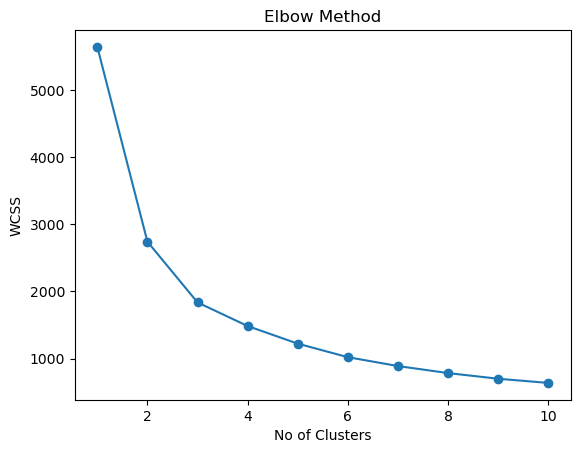

In [5]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans,AgglomerativeClustering
wcss=[]
for i in range(1,11):
    kmeans=KMeans(n_clusters=i,random_state=42,n_init=10)
    kmeans.fit(x_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1,11),wcss,marker='o')
plt.title('Elbow Method')
plt.xlabel('No of Clusters')
plt.ylabel('WCSS')
plt.show()

In [6]:
kmeans=KMeans(n_clusters=3,random_state=42,n_init=10)
y_kmeans= kmeans.fit_predict(x_scaled)
print("Kmeans cluster labels :")
print(y_kmeans)


Kmeans cluster labels :
[1 2 2 ... 0 1 2]


C:\Users\Kartik\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=12.
  warnings.warn(


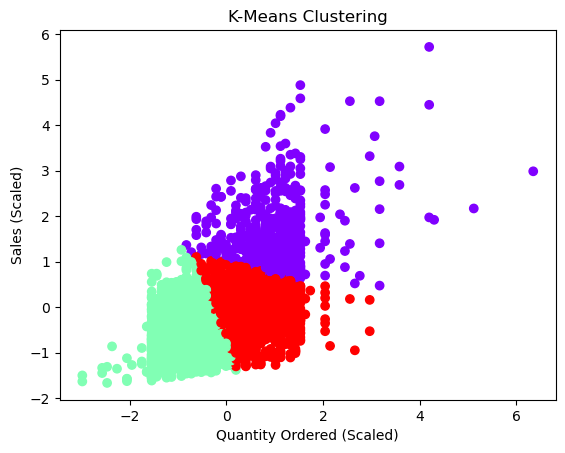

In [7]:
plt.scatter(x_scaled[:,0], x_scaled[:,1],c=y_kmeans,cmap='rainbow')
plt.title('K-Means Clustering')
plt.xlabel('Quantity Ordered (Scaled)')
plt.ylabel('Sales (Scaled)')
plt.show()

In [8]:
hc= AgglomerativeClustering(n_clusters=3,linkage='ward')
y_hc= hc.fit_predict(x_scaled)
print("Hierarchical cluster:")
print(y_hc)

Hierarchical cluster:
[0 0 0 ... 1 0 2]


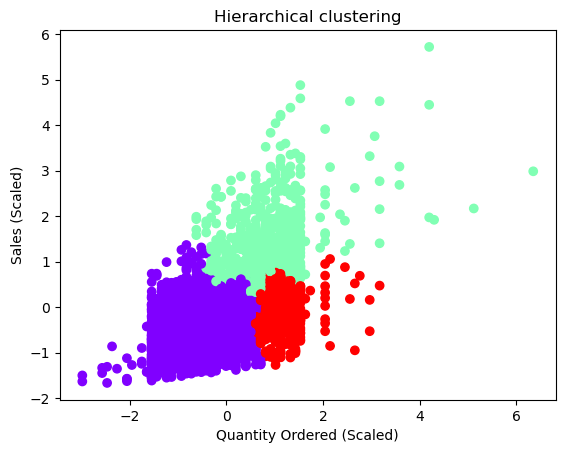

In [9]:
plt.scatter(x_scaled[:,0],x_scaled[:,1],c=y_hc,cmap='rainbow')
plt.title('Hierarchical clustering')
plt.xlabel('Quantity Ordered (Scaled)')
plt.ylabel('Sales (Scaled)')
plt.show()

In [10]:
print("Kmeans count:",pd.Series(y_kmeans).value_counts())
print("Hierarchical count:",pd.Series(y_hc).value_counts())

Kmeans count: 1    1259
2    1044
0     520
Name: count, dtype: int64
Hierarchical count: 0    1735
1     624
2     464
Name: count, dtype: int64
